# 2. Signal generator module (FMCW, TDM-MIMO): `RadarSensorView` + `AntennaModel` → `RadarCpiData`

In [71]:
import matplotlib.pyplot as plt
import numpy as np

from osi_hfss import decode, modules
from osi_hfss.analysis import expected_positions
from osi_hfss.data import load
from osi_hfss.messages import preview
from osi_hfss.plots import plot_beat_signal, plot_chirp_sequence, plot_range_profile, plot_virtual_phase

# The inputs: OSI messages of the environment and the antenna modules
sensor_view = load("front.sensorview.bin")
antenna = load("front.antennamodel.bin")
generator_config = load("front.signal_generator.json")  # generator settings, not part of OSI
rays = sensor_view.radar_sensor_view[0]
expected = expected_positions(rays)  # direct reflections, for comparison only

## Configuration

The generator configuration (`FmcwMimoConfig`) and the waveform it defines are not part of OSI.

In [72]:
description = load("front.generator_description.json")
config, waveform = description["config"], description["waveform"]

T_cpi = config["chirps"] * config["chirp_repetition_interval"]
v_max = waveform["wavelength"] / (4 * len(config["tx_sequence"]) * config["chirp_repetition_interval"])
print(f"{description['generator']} with an {waveform['type']}")
print(f"slope {waveform['slope'] / 1e12:.1f} MHz/us, sampled bandwidth {waveform['sampled_bandwidth'] / 1e6:.0f} MHz")
print(f"range resolution {waveform['range_resolution']:.3f} m, max range {waveform['unambiguous_range']:.1f} m")
print(f"CPI {config['chirps']} chirps = {T_cpi * 1e3:.2f} ms, unambiguous range rate (virtual) ±{v_max:.1f} m/s")
print(f"noise power {10 * np.log10(config['noise_power'] / 1e-3):.1f} dBm per complex sample")

fmcw-signal-generator with an FmcwWaveform
slope 41.7 MHz/us, sampled bandwidth 427 MHz
range resolution 0.351 m, max range 89.9 m
CPI 192 chirps = 2.88 ms, unambiguous range rate (virtual) ±21.7 m/s
noise power -88.0 dBm per complex sample


## Chirp sequence

TDM: the transmitters take turns chirp by chirp.

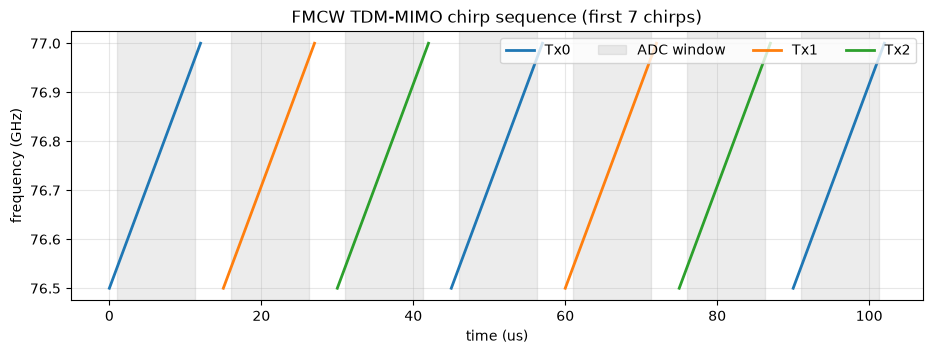

In [73]:
plot_chirp_sequence(config)
plt.show()

## Raw output: PHYSICAL channels, FAST_TIME

The module unpacks the inputs, renders the CPI and packs it into `RadarCpiData` (float32), with the `view_configuration` of the rays echoed.

9 reflections -> CPI (4, 192, 256) (channel, slow, fast) -> RadarCpiData 1.57 MB
channels: [('PHYSICAL', 0, None), ('PHYSICAL', 1, None), ('PHYSICAL', 2, None), ('PHYSICAL', 3, None)]
centre frequency 76.755 GHz, transmitters [0, 1, 2]


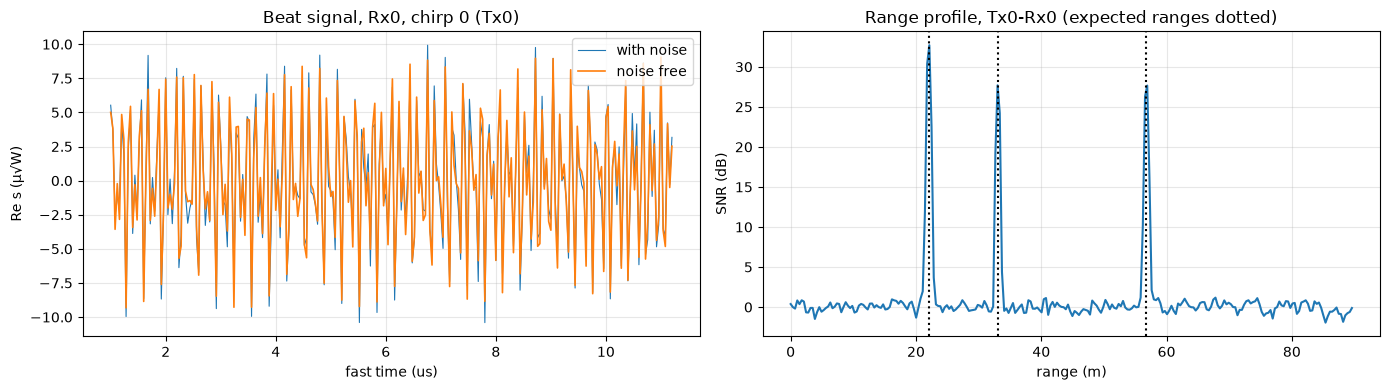

In [74]:
raw_data = modules.fmcw_signal_generator(sensor_view, antenna, generator_config, raw=True)  # configured for the raw ADC output
cpi = raw_data.cpi_frame[0]  # PHYSICAL channels, FAST_TIME
noise_free = modules.fmcw_signal_generator(sensor_view, antenna, generator_config, raw=True, noise_free=True).cpi_frame[0]
cpi_data = modules.fmcw_signal_generator(sensor_view, antenna, generator_config)  # the module output: VIRTUAL channels, RANGE domain
virtual_range = cpi_data.cpi_frame[0]
print(f"{len(rays.reflection)} reflections -> CPI {decode.cpi_cube(cpi).shape} (channel, slow, fast) -> RadarCpiData {raw_data.ByteSize() / 1e6:.2f} MB")
print("channels:", [(decode.enum_name(c, "kind"), c.rx_index, c.tx_index if c.HasField("tx_index") else None) for c in cpi.channel])
print(f"centre frequency {cpi.center_frequency / 1e9:.3f} GHz, transmitters {[t.index for t in cpi.transmitter]}")

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
plot_beat_signal(cpi, noise_free, ax=a)
plot_range_profile(virtual_range, expected, ax=b)
plt.tight_layout(); plt.show()

## Physical vs. virtual channels, signal vs. spectral domain

The CPI interface carries both layouts.

physical         shape (4, 192, 256), fast FAST_TIME step 4e-08, slow SLOW_TIME step 15 us, window NONE
virtual          shape (12, 64, 256), fast RANGE step 0.351, slow SLOW_TIME step 45 us, window HANN

 ch  Rx  Tx   y [mm]  t0 [us]
  0   0   0   -10.74        0
  1   1   0    -8.79        0
  2   2   0    -6.84        0
  3   3   0    -4.88        0
  4   0   1    -2.93       15
  5   1   1    -0.98       15
  6   2   1     0.98       15
  7   3   1     2.93       15
  8   0   2     4.88       30
  9   1   2     6.84       30
 10   2   2     8.79       30
 11   3   2    10.74       30


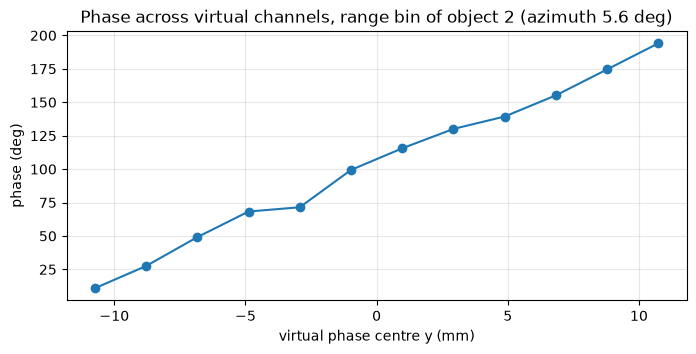

In [75]:
for name, c in (("physical", cpi), ("virtual", virtual_range)):
    print(f"{name:16s} shape {decode.cpi_cube(c).shape}, fast {decode.enum_name(c.fast_axis, 'domain')} step {c.fast_axis.spacing:.3g}, "
          f"slow {decode.enum_name(c.slow_axis, 'domain')} step {c.slow_axis.spacing * 1e6:.0f} us, window {decode.enum_name(c.fast_axis, 'window')}")
print()
print(f"{'ch':>3} {'Rx':>3} {'Tx':>3} {'y [mm]':>8} {'t0 [us]':>8}")
for c in virtual_range.channel:
    print(f"{c.index:3d} {c.rx_index:3d} {c.tx_index:3d} {c.position.y * 1e3:8.2f} {c.time_offset * 1e6:8.0f}")

plot_virtual_phase(virtual_range, max(expected, key=lambda e: e.distance))
plt.show()

## Output on the interface: OSI `RadarCpiData`

This is what the generator hands to the DSP.

In [76]:
print(preview(raw_data, max_repeated=1))

version {
  version_major: 3
  version_minor: 8
  version_patch: 0
}
timestamp {
  seconds: 0
  nanos: 2880000
}
sensor_id {
  value: 100
}
view_configuration {
  sensor_id {
    value: 100
  }
  mounting_position {
    position {
      x: 3.5
      y: 0
      z: 0.5
    }
    orientation {
      yaw: 0
    }
  }
  field_of_view_horizontal: 2.0944
  field_of_view_vertical: 0.349066
  emitter_frequency: 7.675e+10
  antenna_application: ANTENNA_APPLICATION_SENSOR_MODEL
}
cpi_frame {
  cpi_index: 0
  start_time {
    seconds: 0
    nanos: 0
  }
  fast_axis {
    domain: DOMAIN_FAST_TIME
    size: 256
    spacing: 4e-08
    offset: 1e-06
    window: WINDOW_NONE
  }
  slow_axis {
    domain: DOMAIN_SLOW_TIME
    size: 192
    spacing: 1.5e-05
    offset: 0
    window: WINDOW_NONE
  }
  channel {
    index: 0
    kind: KIND_PHYSICAL
    rx_index: 0
    position {
      x: 0
      y: -0.00292957
      z: 0
    }
    time_offset: 0
    rx_port: 0
  }
  channel: ... 3 more
  transmitter {
    i